# 08 — Publication Figures (post-hoc)

**Purpose:** Generate publication-ready figures for Lancet Psychiatry submission, separate from primary analytical notebooks.

This notebook **does not modify any primary analyses**. It re-loads data (using the same load_country_category function from notebook 02_H2a) and re-creates the OLS fit to produce two separate figure files:

- **Figure 2** (main text): Global mean RSV trend + per-country trajectories (panels A, B from notebook 02 — top row).
- **Figure S1** (supplementary): Diagnostic plots — residuals vs fitted, Q-Q plot (panels C, D from notebook 02 — bottom row).

Output: 300 dpi PNG files in `../results/publication/`.

This file is NOT part of the pre-registered analysis pipeline; it serves only to format figures for journal submission. No new statistical inferences are performed.


## 1. Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from scipy import stats
from pathlib import Path

warnings.filterwarnings('ignore')

# Paths
DATA_DIR    = Path('../data')
OUTPUT_DIR  = Path('../results/publication')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameters (match 02_H2a_absolute_trend.ipynb)
CATEGORY    = 'evidence_based_treatments'
DPI         = 300  # Lancet requires >=300 dpi for figures

print(f'Output dir: {OUTPUT_DIR.resolve()}')
print(f'DPI:        {DPI}')


Output dir: C:\Users\YS\Documents\STORAGE\Research\psych-help-trends\results\publication
DPI:        300


## 2. Load data

Replica of 02_H2a — same load function, same filter (>20% missing → exclude).

In [2]:
def load_country_category(country_dir: Path, category: str):
    """Identical to 02_H2a — replicated here for self-containment."""
    csv_files = sorted(country_dir.glob(f'{category}__*__chunk*.csv'))
    if not csv_files:
        return None
    frames = []
    for f in csv_files:
        try:
            df = pd.read_csv(f, parse_dates=['date'], index_col='date')
            if 'isPartial' in df.columns:
                df = df[df['isPartial'] == False].drop(columns=['isPartial'])
            df = df.replace(0, np.nan)
            df = df.drop(columns=df.columns[df.isna().all()])
            if not df.empty and df.shape[1] > 0:
                frames.append(df)
        except Exception as e:
            print(f'  Warning: {f.name}: {e}')
    if not frames:
        return None
    return pd.concat(frames, axis=1)


# Find latest data folder
LATEST = sorted(DATA_DIR.glob('raw_*'))[-1]
print(f'Data folder: {LATEST.name}')

# Load all countries (same filter as 02_H2a: drop if >20% missing)
country_series = {}
for country_dir in sorted([d for d in LATEST.iterdir() if d.is_dir()]):
    code = country_dir.name
    df = load_country_category(country_dir, CATEGORY)
    if df is None:
        continue
    series = df.mean(axis=1)
    if series.isna().mean() <= 0.20:
        country_series[code] = series

panel = pd.DataFrame(country_series).sort_index()
panel.index = pd.to_datetime(panel.index)

y_global = panel.mean(axis=1)

print(f'\nN countries: {panel.shape[1]}')
print(f'N months:    {len(y_global)}')
print(f'Range:       {y_global.index[0].date()} -> {y_global.index[-1].date()}')


Data folder: raw_20260417_211800

N countries: 21
N months:    96
Range:       2018-01-01 -> 2025-12-01


## 3. Fit OLS

Replica — produces same coefficients as primary analysis.

In [3]:
# Fit OLS (replicates 02_H2a)
mask  = ~y_global.isna()
y_ols = y_global[mask].values
t     = np.arange(len(y_global))
t_ols = t[mask]

X     = sm.add_constant(t_ols)
model = sm.OLS(y_ols, X).fit()

beta0 = model.params[0]
beta1 = model.params[1]
p_val = model.pvalues[1]
r2    = model.rsquared

residuals = model.resid
sw_stat, sw_p = stats.shapiro(residuals)

print(f'OLS: beta1 = {beta1:.4f}, p = {p_val:.4g}, R^2 = {r2:.4f}')
print(f'Shapiro-Wilk p = {sw_p:.4g}')


OLS: beta1 = 0.1364, p = 4.719e-18, R^2 = 0.5515
Shapiro-Wilk p = 3.916e-08


## 4. Figure 2 (main text)

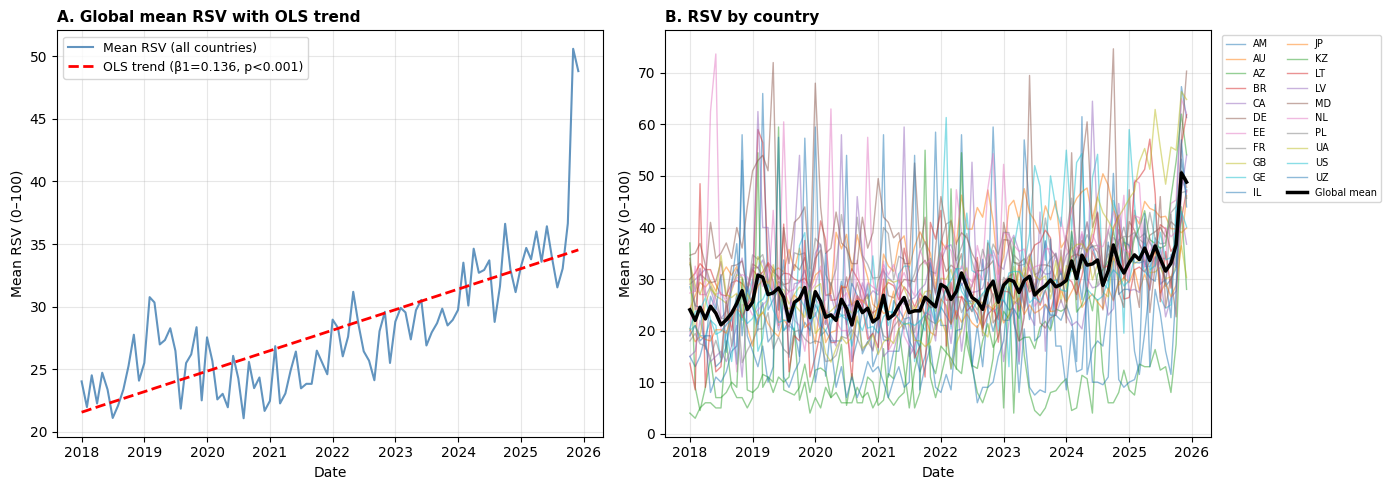

Saved: ..\results\publication\Figure2_main.png


In [4]:
# ----------------------------------------------------------------------
# Figure 2 (main text) — panels A and B only
# Panel A: Global mean RSV with OLS trend
# Panel B: RSV trajectories by country with global mean overlaid
# ----------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Panel A: Global mean trend ----
ax1 = axes[0]
ax1.plot(y_global.index, y_global.values,
         color='steelblue', linewidth=1.5, alpha=0.85,
         label='Mean RSV (all countries)')
y_fit_full = beta0 + beta1 * t
ax1.plot(y_global.index, y_fit_full,
         color='red', linewidth=2, linestyle='--',
         label=f'OLS trend (β1={beta1:.3f}, p<0.001)')
ax1.set_title('A. Global mean RSV with OLS trend', loc='left',
              fontsize=11, fontweight='bold')
ax1.set_xlabel('Date')
ax1.set_ylabel('Mean RSV (0–100)')
ax1.legend(fontsize=9, loc='upper left')
ax1.grid(alpha=0.3)
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# ---- Panel B: Per-country with global mean overlaid ----
ax2 = axes[1]
for col in panel.columns:
    ax2.plot(panel.index, panel[col], linewidth=1, alpha=0.5, label=col)
ax2.plot(y_global.index, y_global.values,
         color='black', linewidth=2.5, label='Global mean', zorder=5)
ax2.set_title('B. RSV by country', loc='left',
              fontsize=11, fontweight='bold')
ax2.set_xlabel('Date')
ax2.set_ylabel('Mean RSV (0–100)')
ax2.legend(fontsize=7, ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
ax2.grid(alpha=0.3)
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
fig2_path = OUTPUT_DIR / 'Figure2_main.png'
fig.savefig(fig2_path, dpi=DPI, bbox_inches='tight')
plt.show()

print(f'Saved: {fig2_path}')


## 5. Figure S1 (supplementary diagnostics)

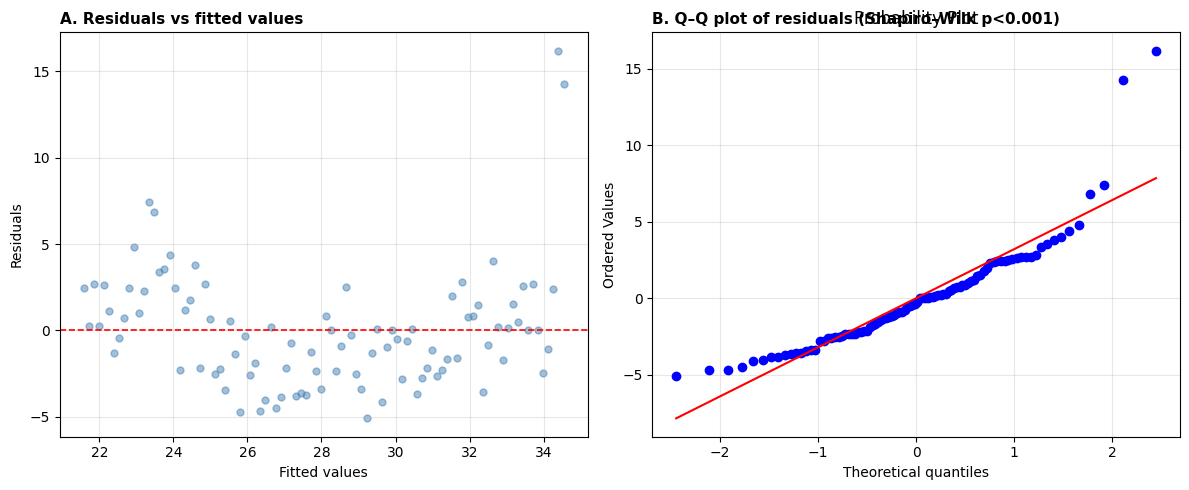

Saved: ..\results\publication\FigureS1_diagnostics.png


In [5]:
# ----------------------------------------------------------------------
# Figure S1 (supplementary) — diagnostic plots
# Panel A: Residuals vs Fitted (homoscedasticity check)
# Panel B: Q-Q plot of residuals (normality check)
# ----------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ---- Panel A: Residuals vs Fitted ----
ax1 = axes[0]
ax1.scatter(model.fittedvalues, residuals,
            alpha=0.5, color='steelblue', s=25)
ax1.axhline(0, color='red', linestyle='--', linewidth=1.2)
ax1.set_title('A. Residuals vs fitted values', loc='left',
              fontsize=11, fontweight='bold')
ax1.set_xlabel('Fitted values')
ax1.set_ylabel('Residuals')
ax1.grid(alpha=0.3)

# ---- Panel B: Q-Q plot ----
ax2 = axes[1]
stats.probplot(residuals, dist='norm', plot=ax2)
ax2.set_title(f'B. Q–Q plot of residuals (Shapiro–Wilk p<0.001)',
              loc='left', fontsize=11, fontweight='bold')
ax2.grid(alpha=0.3)

plt.tight_layout()
figs1_path = OUTPUT_DIR / 'FigureS1_diagnostics.png'
fig.savefig(figs1_path, dpi=DPI, bbox_inches='tight')
plt.show()

print(f'Saved: {figs1_path}')


## 6. Done

In [6]:
print('=' * 60)
print('Publication figures generated successfully.')
print('=' * 60)
print(f'  Figure 2 (main text):       {OUTPUT_DIR / "Figure2_main.png"}')
print(f'  Figure S1 (supplementary):  {OUTPUT_DIR / "FigureS1_diagnostics.png"}')
print()
print('Both files at 300 dpi (Lancet requirement).')
print('Primary H2a results NOT modified.')


Publication figures generated successfully.
  Figure 2 (main text):       ..\results\publication\Figure2_main.png
  Figure S1 (supplementary):  ..\results\publication\FigureS1_diagnostics.png

Both files at 300 dpi (Lancet requirement).
Primary H2a results NOT modified.
